# 09 · EPA AirNow – hourly PM2.5 during the June 2023 wildfire smoke

**Utility for the City Brain: high** · Domain: air quality · Incident types: `fire` (ambiguous case)

> A real air-quality event: Canadian wildfire smoke over New York. It shows the shape and scale of smoke, and the trap of a city-wide rise that is *not* a local fire.

| | |
|---|---|
| **Source** | US EPA AirNow hourly files, https://files.airnowtech.org (1–14 June 2023) |
| **Licence** | Public (US government); data are preliminary, acknowledge AirNow |
| **In this repo** | Sample: PM2.5 rows of New York and New Jersey agencies (`data/air-quality/airnow-smoke/pm25_jun2023_nynj.dat.gz`) |
| **Get it** | https://files.airnowtech.org/airnow/2023/20230601/HourlyData_2023060100.dat (one file per hour) |

Legend used in the last section: **Detect** = detection rules (`brain/src/detection/`), **Graph** = graph DB (`brain/src/graph/`), **Mock** = realistic replay for mock sensors, **Scenarios** = test / demo cases, **Eval** = measure the Brain on data not used to tune it, **Score** = numbers for the scoring model.

In [1]:
import sys, json, gzip, re
from pathlib import Path
sys.path.insert(0, '..')
from cbdata import path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 3.6), 'axes.grid': True, 'grid.alpha': .3})

## 1. What's inside

Pipe-separated, no header: `date | time (UTC) | site id | site name | UTC offset | parameter | unit | value | agency`.

In [2]:
a = pd.read_csv(path('air-quality/airnow-smoke/pm25_jun2023_nynj.dat.gz'), sep='|', header=None,
                names=['date', 'time', 'site', 'name', 'utc_offset', 'param', 'unit', 'value', 'agency'])
a['ts'] = pd.to_datetime(a.date + ' ' + a.time, format='%m/%d/%y %H:%M')
a = a[(a.param == 'PM2.5') & (a.value >= 0)]
print(f"{len(a):,} readings · {a.site.nunique()} sites"); a.head()

12,482 readings · 42 sites


,date,time,site,name,utc_offset,param,unit,value,agency,ts
0,06/01/23,00:00,340010006,Brigantine,-5,PM2.5,UG/M3,10.7,New Jersey Dept. of Environmental Protection,2023-06-01
1,06/01/23,00:00,340030010,Fort Lee Near Road,-5,PM2.5,UG/M3,13.3,New Jersey Dept. of Environmental Protection,2023-06-01
2,06/01/23,00:00,340070002,Camden Spruce St,-5,PM2.5,UG/M3,34.1,New Jersey Dept. of Environmental Protection,2023-06-01
3,06/01/23,00:00,340110007,Millville,-5,PM2.5,UG/M3,9.0,New Jersey Dept. of Environmental Protection,2023-06-01
4,06/01/23,00:00,340171003,Jersey City FH,-5,PM2.5,UG/M3,11.5,New Jersey Dept. of Environmental Protection,2023-06-01


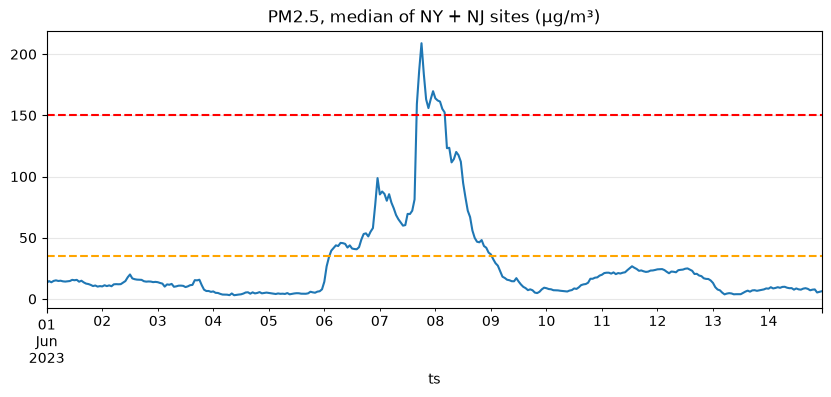

Baseline 1-4 June: median 11.5 µg/m³, normal 1-h change p99 3.9
Peak: 209 at 2023-06-07 18:00:00 (UTC); highest single site 488
Fastest 1-h rise: +78 (20 x normal p99)
Hours above 35.5: 70 · above 150.5: 13


In [3]:
hourly = a.pivot_table(index='ts', columns='site', values='value')
med = hourly.median(axis=1)
ax = med.plot(title='PM2.5, median of NY + NJ sites (µg/m³)'); ax.axhline(35.5, ls='--', c='orange'); ax.axhline(150.5, ls='--', c='r'); plt.show()
base = med.loc[:'2023-06-04']; step = base.diff().abs()
print(f"Baseline 1-4 June: median {base.median():.1f} µg/m³, normal 1-h change p99 {step.quantile(.99):.1f}")
print(f"Peak: {med.max():.0f} at {med.idxmax()} (UTC); highest single site {hourly.max().max():.0f}")
print(f"Fastest 1-h rise: +{med.diff().max():.0f} ({med.diff().max() / step.quantile(.99):.0f} x normal p99)")
print('Hours above 35.5:', int((med > 35.5).sum()), '· above 150.5:', int((med > 150.5).sum()))

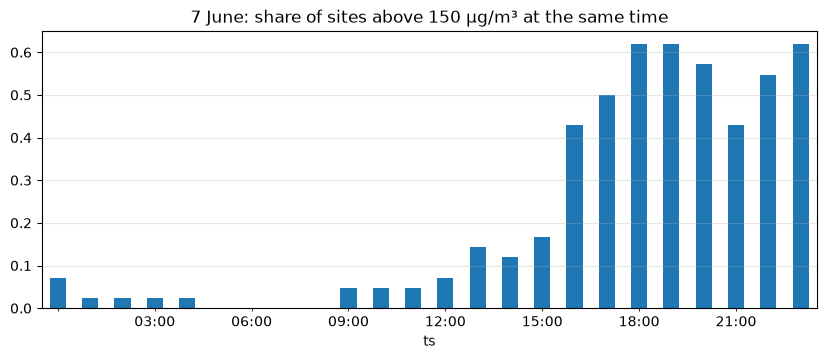

In [4]:
share = (hourly.loc['2023-06-07'] > 150.5).mean(axis=1)
share.plot(kind='bar', title='7 June: share of sites above 150 µg/m³ at the same time'); plt.xticks([]); plt.show()

**Almost every site goes extreme at the same time.** For the City Brain, a city-wide rise with no fire call and no local second signal is **regional smoke**, not a fire in a zone.

## 2. What it means for the City Brain

| Use | How |
|---|---|
| **Detect** | Normal 1-h change is a few µg/m³ (p99 ≈ 4 here); smoke rose ~80 per hour on the regional median (+132 per hour at NYC sites). Many zones rising together + no call = regional smoke (warn, don't open `fire`) |
| **Mock** | Real smoke curve for `air_quality` sensors (scale and decay over 2 days) |
| **Scenarios** | The ambiguous case "air quality extreme everywhere, no fire" |

**Limits:** hourly, outdoor stations; preliminary data.